<a href="https://colab.research.google.com/github/narayn02/Codealpha_tasks/blob/main/Unemployment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["figure.dpi"] = 110

OUTPUT_DIR = Path("unemployment_project_output")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Unemployment Analysis Project Started")

Unemployment Analysis Project Started


In [2]:
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Original dataset shape:", df.shape)

display(df.head())

Saving Unemployment in India.csv to Unemployment in India.csv
Dataset loaded successfully!
Original dataset shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


CLEAN THE DATA

In [3]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert dates
df["Date"] = pd.to_datetime(
    df["Date"],
    dayfirst=True,
    errors="coerce"
)

# Convert numerical columns
numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values before cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

df = df.dropna(subset=[
    "Region",
    "Date",
    "Area",
    "Estimated Unemployment Rate (%)"
]).copy()

df["Region"] = df["Region"].astype(str).str.strip()
df["Area"] = df["Area"].astype(str).str.strip()

df = df.sort_values("Date").reset_index(drop=True)

print("\nCleaned dataset shape:", df.shape)
display(df.head())

Missing values before cleaning:


,Missing Values
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


Duplicate rows: 27

Cleaned dataset shape: (740, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Telangana,2019-05-31,Monthly,2.23,11053353.0,61.74,Rural
2,Tamil Nadu,2019-05-31,Monthly,0.97,15844698.0,49.44,Rural
3,Rajasthan,2019-05-31,Monthly,4.03,15226005.0,38.52,Rural
4,Punjab,2019-05-31,Monthly,9.17,6088547.0,44.79,Rural


In [4]:
unemployment_col = "Estimated Unemployment Rate (%)"

average_rate = df[unemployment_col].mean()
median_rate = df[unemployment_col].median()
highest_rate = df[unemployment_col].max()
lowest_rate = df[unemployment_col].min()

print("=" * 50)
print("       UNEMPLOYMENT DATA OVERVIEW")
print("=" * 50)

print(f"Total records: {len(df)}")
print(f"Regions covered: {df['Region'].nunique()}")
print(f"Date range: {df['Date'].min():%d %b %Y} "
      f"to {df['Date'].max():%d %b %Y}")
print(f"Average recorded unemployment rate: {average_rate:.2f}%")
print(f"Median recorded unemployment rate: {median_rate:.2f}%")
print(f"Highest recorded rate: {highest_rate:.2f}%")
print(f"Lowest recorded rate: {lowest_rate:.2f}%")

       UNEMPLOYMENT DATA OVERVIEW
Total records: 740
Regions covered: 28
Date range: 31 May 2019 to 30 Jun 2020
Average recorded unemployment rate: 11.79%
Median recorded unemployment rate: 8.35%
Highest recorded rate: 76.74%
Lowest recorded rate: 0.00%


UNEMPLOYMENT RATE DISTRIBUTION

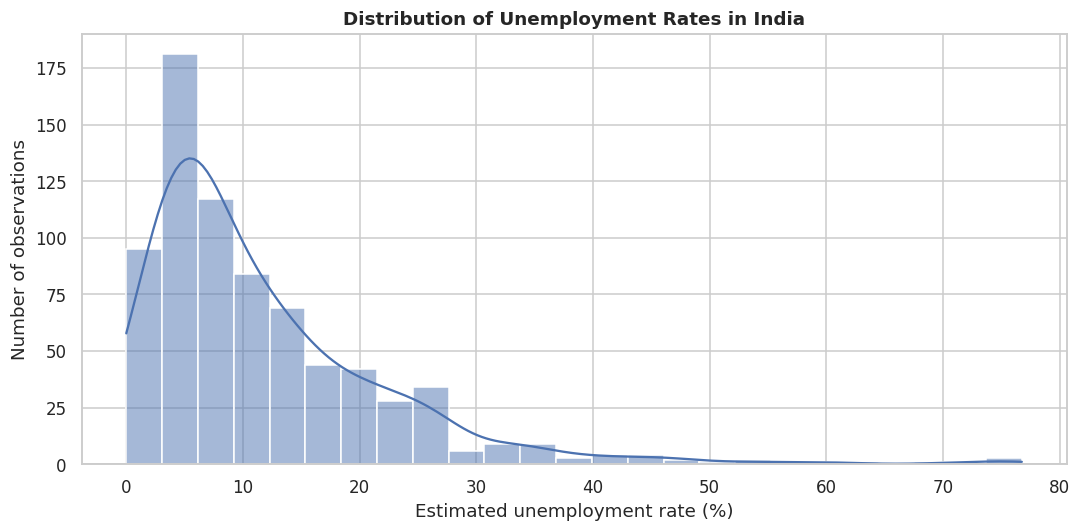

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x=unemployment_col,
    bins=25,
    kde=True
)

plt.title("Distribution of Unemployment Rates in India")
plt.xlabel("Estimated unemployment rate (%)")
plt.ylabel("Number of observations")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "01_unemployment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

UNEMPLOYMENT TREND OVER TIME

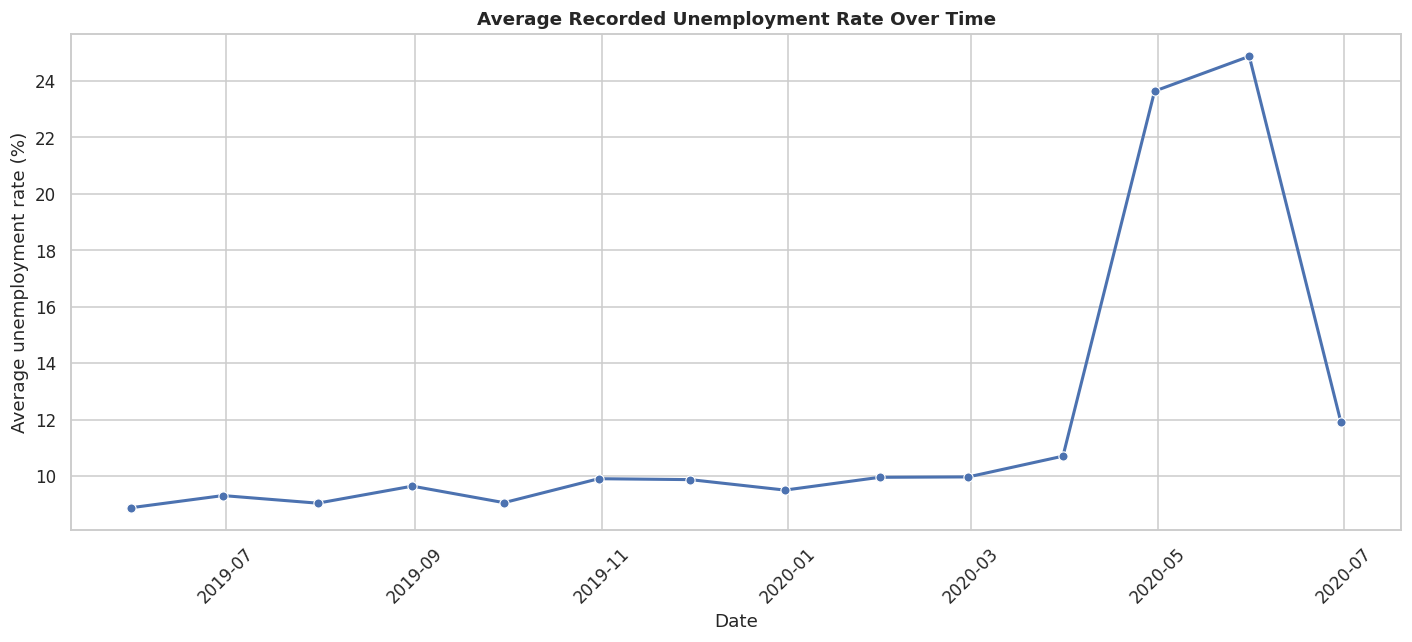

In [6]:
date_trend = (
    df.groupby("Date")[unemployment_col]
    .mean()
    .reset_index()
    .sort_values("Date")
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=date_trend,
    x="Date",
    y=unemployment_col,
    marker="o",
    linewidth=2
)

plt.title("Average Recorded Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Average unemployment rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "02_unemployment_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

REGION-WISE UNEMLOYMENT RANKING

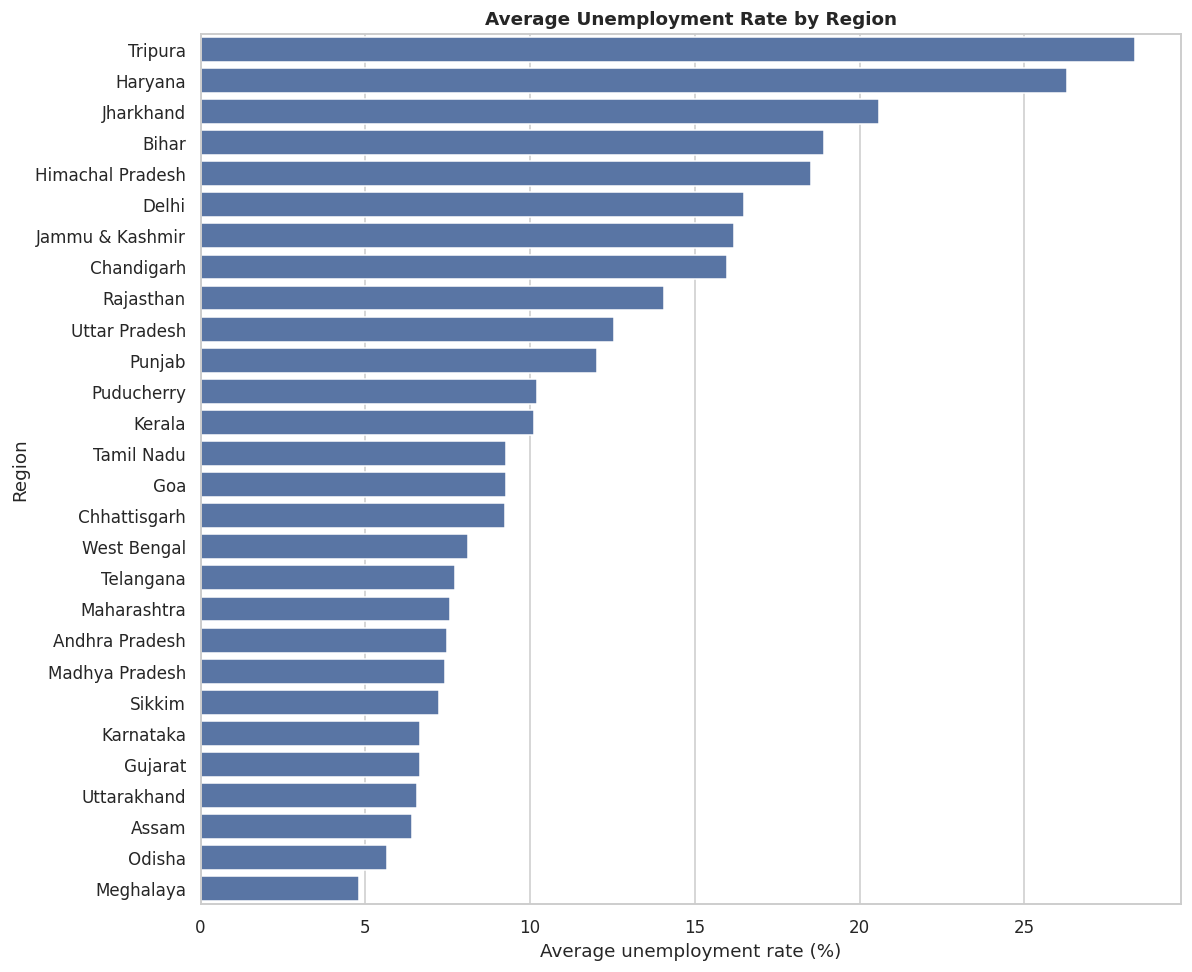

,Region,Estimated Unemployment Rate (%)
0,Tripura,28.35
1,Haryana,26.28
2,Jharkhand,20.58
3,Bihar,18.92
4,Himachal Pradesh,18.54
5,Delhi,16.50
6,Jammu & Kashmir,16.19
7,Chandigarh,15.99
8,Rajasthan,14.06
9,Uttar Pradesh,12.55


In [7]:
region_data = (
    df.groupby("Region")[unemployment_col]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(11, 9))

sns.barplot(
    data=region_data,
    x=unemployment_col,
    y="Region"
)

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average unemployment rate (%)")
plt.ylabel("Region")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "03_region_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(region_data.round(2))

RURAL AND URBAN COMPARISION

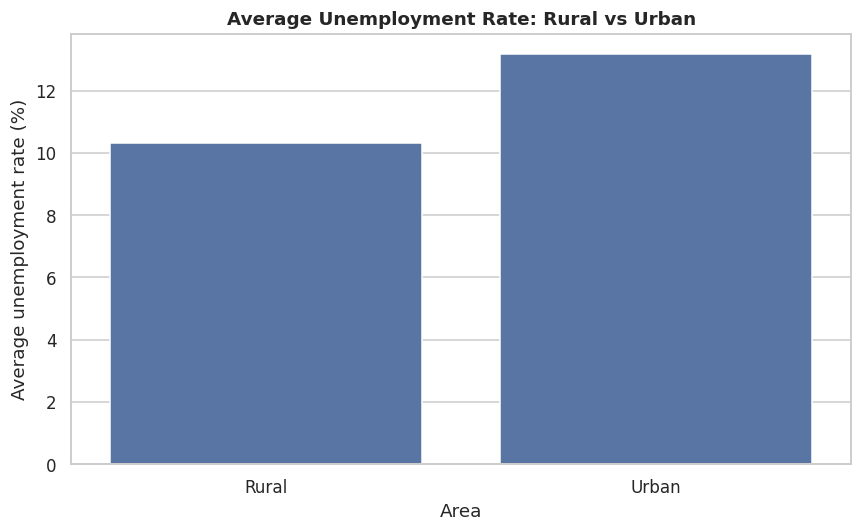

,Area,Average Rate,Median Rate,Number of Records
0,Rural,10.32,6.76,359
1,Urban,13.17,9.97,381


In [8]:
area_data = (
    df.groupby("Area")[unemployment_col]
    .agg(["mean", "median", "count"])
    .reset_index()
)

area_data.columns = [
    "Area",
    "Average Rate",
    "Median Rate",
    "Number of Records"
]

plt.figure(figsize=(8, 5))

sns.barplot(
    data=area_data,
    x="Area",
    y="Average Rate"
)

plt.title("Average Unemployment Rate: Rural vs Urban")
plt.xlabel("Area")
plt.ylabel("Average unemployment rate (%)")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "04_rural_urban_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(area_data.round(2))

COMPARE RURAL AND URBAN TRENDS

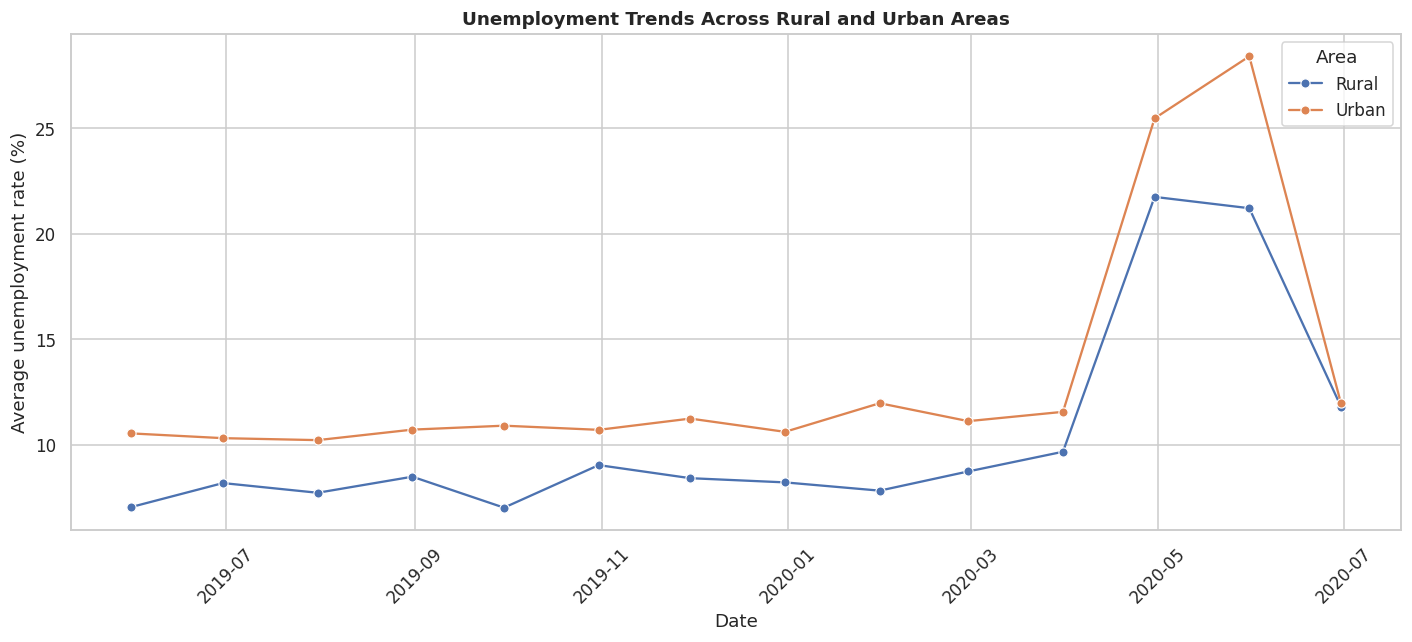

In [9]:
area_trend = (
    df.groupby(["Date", "Area"])[unemployment_col]
    .mean()
    .reset_index()
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=area_trend,
    x="Date",
    y=unemployment_col,
    hue="Area",
    marker="o"
)

plt.title("Unemployment Trends Across Rural and Urban Areas")
plt.xlabel("Date")
plt.ylabel("Average unemployment rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "05_area_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

MONTHLY TREND AND SEASONAL PATTERNS

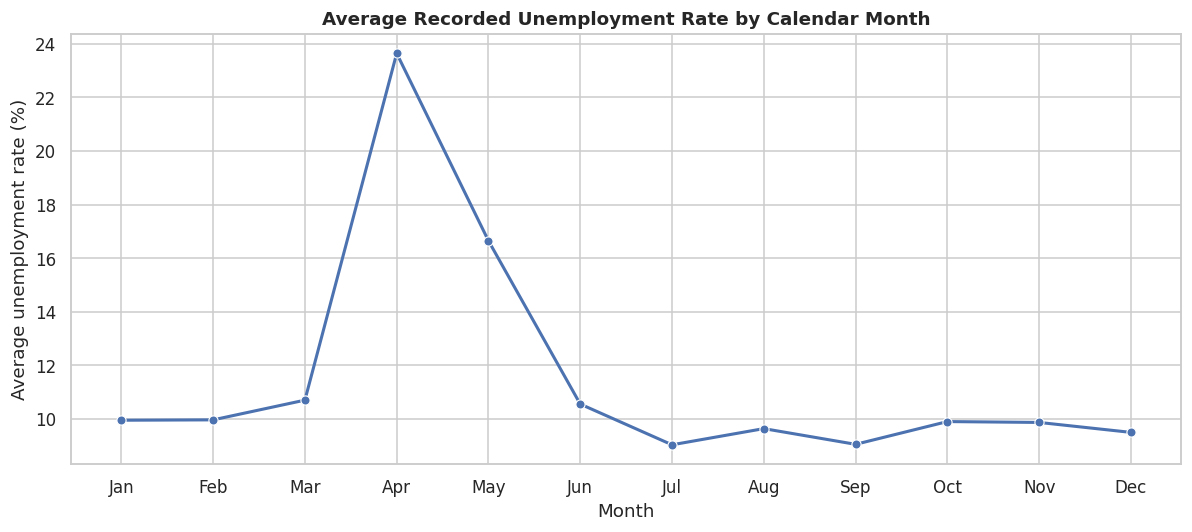

In [10]:
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year

monthly_data = (
    df.groupby("Month")[unemployment_col]
    .mean()
    .reindex(range(1, 13))
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(11, 5))

sns.lineplot(
    x=month_names,
    y=monthly_data.values,
    marker="o",
    linewidth=2
)

plt.title("Average Recorded Unemployment Rate by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average unemployment rate (%)")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "07_monthly_pattern.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

LABOUR PARTICIPATION AND UNEMPLOYMENT

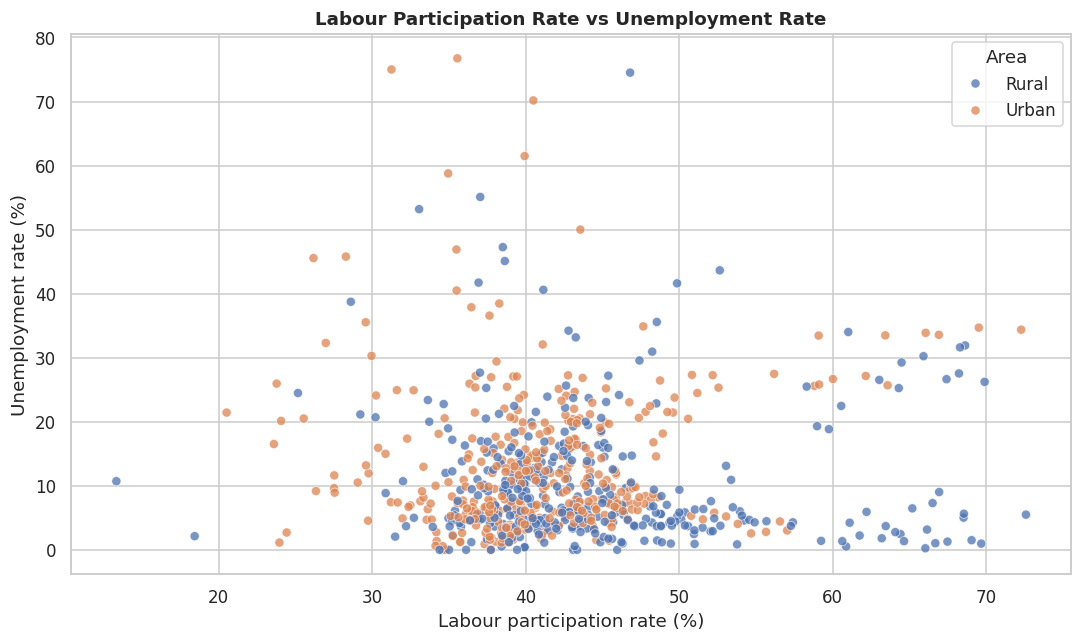

In [11]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Estimated Labour Participation Rate (%)",
    y=unemployment_col,
    hue="Area",
    alpha=0.75
)

plt.title("Labour Participation Rate vs Unemployment Rate")
plt.xlabel("Labour participation rate (%)")
plt.ylabel("Unemployment rate (%)")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "08_participation_relationship.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

CORRELATION HEATMAP

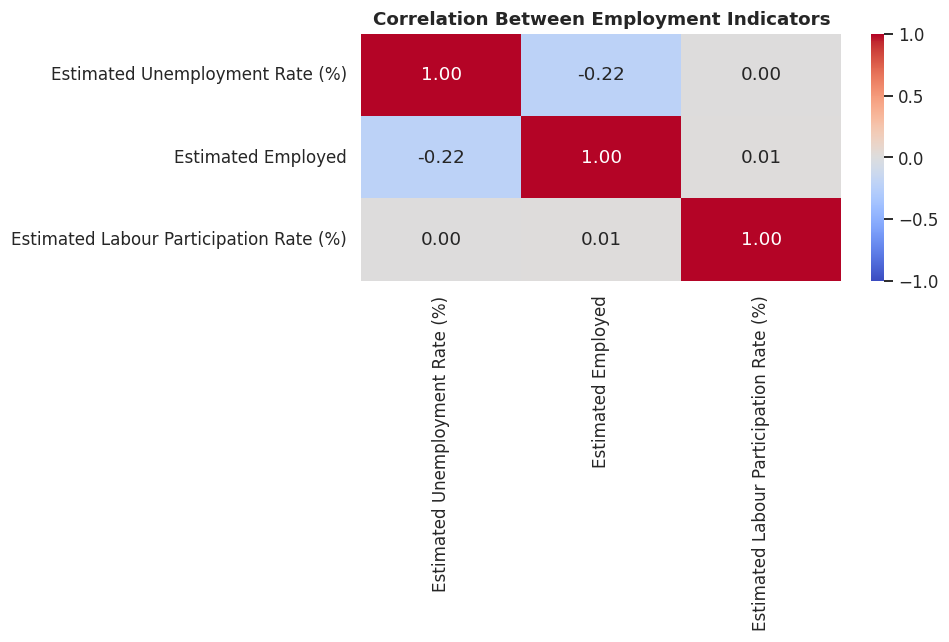

In [12]:
correlation_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation = df[correlation_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Employment Indicators")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "09_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Automatic Insight From the Data

In [13]:
region_avg = (
    df.groupby("Region")[unemployment_col]
    .mean()
    .sort_values(ascending=False)
)

date_avg = (
    df.groupby("Date")[unemployment_col]
    .mean()
)

area_avg = (
    df.groupby("Area")[unemployment_col]
    .mean()
)

print("=" * 55)
print("             PROJECT FINDINGS")
print("=" * 55)

print(
    f"\nHighest average regional rate: {region_avg.index[0]} "
    f"({region_avg.iloc[0]:.2f}%)"
)

print(
    f"Lowest average regional rate: {region_avg.index[-1]} "
    f"({region_avg.iloc[-1]:.2f}%)"
)

print(
    f"\nHighest average recorded rate by date: "
    f"{date_avg.idxmax():%d %b %Y} ({date_avg.max():.2f}%)"
)

print(
    f"Lowest average recorded rate by date: "
    f"{date_avg.idxmin():%d %b %Y} ({date_avg.min():.2f}%)"
)

print("\nAverage unemployment rate by area:")
for area, rate in area_avg.items():
    print(f"{area}: {rate:.2f}%")

if len(area_avg) >= 2:
    difference = area_avg.max() - area_avg.min()
    print(f"\nDifference between highest and lowest area averages: "
          f"{difference:.2f} percentage points")

             PROJECT FINDINGS

Highest average regional rate: Tripura (28.35%)
Lowest average regional rate: Meghalaya (4.80%)

Highest average recorded rate by date: 31 May 2020 (24.88%)
Lowest average recorded rate by date: 31 May 2019 (8.87%)

Average unemployment rate by area:
Rural: 10.32%
Urban: 13.17%

Difference between highest and lowest area averages: 2.84 percentage points


EXPORT THE ANALYSIS TREND

In [15]:
df.to_csv(
    OUTPUT_DIR / "cleaned_unemployment_data.csv",
    index=False
)

region_data.to_csv(
    OUTPUT_DIR / "regional_analysis.csv",
    index=False
)

area_data.to_csv(
    OUTPUT_DIR / "area_analysis.csv",
    index=False
)

date_trend.to_csv(
    OUTPUT_DIR / "date_trend.csv",
    index=False
)


print("Analysis tables saved successfully.")

Analysis tables saved successfully.
